# TP4 - Background Substraction
ATRIM - Option Datasim

Ecole Centrale Nantes

Diana Mateus

Participants : Florian et Hugo

## BACKGROUND SUBSTRACTION

The goal of this TP is to enhance the video of a neurointervention  to improve the visualization of moving tools. To this end you will implement a pipeline of image processing methods to detect the moving tools automatically.

-------

### Methodology

As the brain is mostly static one way to detect the moving tools is to substract the background (first image) from each of the subsequent images. However, the results of this step need to be further improved. To this end, you will design a pipilene with the methods learnt in this course to produce a binary mask for the pixels that belong to the tools.

In your pipeline use at least:
- one histogram transformation
- one morphological operation
- one filtering operation in the spatial domain
- one filtering operation in the spectral domain
- one segmentation method

_The same pipeline should be applied to every image!!!!!_

-------

### Expected output

The output of your image processing pipeline should be one binary image mask (with values 0 or 1) for every input image of the sequence, where
- the zero valued pixels indicate the moving tools inside each image.  
- the pixels with value 1 indicate the background (not a moving tool)

To validate the proposed method, a human has annotated (manually drawn) the tools of interest within the images. The annotated pixels belong either to catheters or guidewires. **Your masks should be as close as possible to the human annotations.**

-------

### Visualization of data and manual annotations

- Data visualization  (**do not include in final version**): visualize the neurointervention images in the ``` catheter``` folder with name ```frame_#```

- Individual Annotation visualization  (** do not include in final version**): visualize the manual annotations in the ```catheter``` folder with names ``` #_MicroCath``` and ```#_GuideWire```.

- Joint annotation visualization  (** do not include in final version**): visualize the full manual annotation (union of the guidewire and microcatheter masks) by composing the union of the ``` #_MicroCath``` and ```#_GuideWire```. It should also be a binary mask. Dilate the mask to account for manual error
    ```
    selem = disk(2)
    gt_mask = dilation(gt_mask, selem)
    ```
-------

### Experimental Validation (quantitative and qualitative)

To compare your results and the manual annotations use the mean SAD (Sum of Absolute Differences) and the SNR (Signal to Noise Ratio) errors between your  mask and  the **full** manual mask.

Present the results qualitatively and quantitatively:

- Qualitatively:
     - Show your mask side by side with the manually annotated mask
     - Create an enhanced image suitable for guidance: enhance the contrast of the image and overlay your mask on the green channel of the enhanced image.

- Quantitatively: Compare the estimated mask against the mask generated manually
    - compute and print the SAD (sum of absolute differences) error per image.
    - compute and print the MSE (sum of squared  differences ) error per image.
    - compute and print the PSNR (Peak signal to noise ratio) taking as reference image the manual annotations.
    - plot the errors vs time
    - Then compute and print the mean and standard deviation of each measure (SAD, MSE and PSNR) over the entire sequence.
    
    
Hints:
```
mse = numpy.mean( (img1 - img2) ** 2 )
PIXEL_MAX = 255.0 #or 1.0 or max over the signal of interest
psnr = 20 * math.log10(PIXEL_MAX / math.sqrt(mse))
```
or look at ```skimage.measure``` module

You may use modules such as ```scipy```, ```skimage``` or ``sklearn``(e.g. for clustering with K-means or a Gaussian Mixture Model). Ask me for other external modules.


### REPORT INSTRUCTIONS

#### 1. Intermediate Steps (Code and Description)
Report the results of the intermediate steps (when you add or remove a method from the pipeline):
- provide a text introduction with the idea that you intend to try
- show the implementation of the idea with code
- evaluate the quantitative and qualitative changes  when including, varying, adapting, etc the proposed method
- Discuss the scores or visualization improvements/degradations

#### 2. Final Pipeline (Code and Description)
Provide a detailed description of the best performing pipeline. Comment the code such that it is straightforward to relate the pipeline description to the code. Add your conclusions

- Describe the final retained pipeline
- Give a justification for every step (e.g. supported by experimental intermediate steps or theory).
- Add the **commented** code
- Display the qualitative and quantitative results
- Give your conclusions

# Compte rendu · Soustraction de fond en fluoroscopie

**Compte rendu du TP — Florian BARBE et Hugo AGOSTINI**

L’objectif est de faire ressortir les instruments sur une séquence de neurointervention. Nous cherchons à segmenter le fil-guide (guidewire) et le microcathéter, puis nous comparons les masques aux annotations du TP.

Nous utilisons `frame_201.png` comme image de fond pour la segmentation complète. Les résultats concernent les neuf images 211 à 291.

In [ ]:
from pathlib import Path
from IPython.display import Image, display

RESULTS = Path("results")

def afficher(nom, largeur=None):
    chemin = RESULTS / nom
    if not chemin.is_file():
        raise FileNotFoundError(
            f"{chemin} introuvable. Ouvrir le notebook à la racine du projet "
            "et générer les résultats avec main.py."
        )
    largeur = largeur or (850 if "comparaison_" in chemin.name or "etapes_" in chemin.name else 512)
    display(Image(filename=str(chemin), width=largeur))

## 1. Méthode et essais intermédiaires

Chaque planche montre l’image ou le masque à la sortie de l’opération étudiée. Nous choisissons les réglages en observant le grain du fond, la visibilité du tracé et sa continuité. La validation du pipeline complet est présentée en partie 2.

### 1.1 Vue d’ensemble du pipeline

Nous appliquons les mêmes étapes à chacune des neuf radiographies, avec l’image 201 comme référence fixe.

```mermaid
flowchart TD
    I["Radiographie courante"] --> D["Soustraction avec la référence fixe 201"]
    D --> F["Filtre gaussien spatial 5×5 · σ = 1"]
    F --> P["Filtrage de Fourier · passe-bande gaussien puis retour à l’image"]
    P --> H["Partie positive et étirement au 99ᵉ percentile"]
    H --> T["Seuillage Otsu + 30 · masque binaire"]
    T --> CC["Composantes connexes en 8-connexité · aire ≥ 300 pixels"]
    CC --> K["Fermeture elliptique 3×3"]
    K --> B["Exclusion des trois zones de bord"]
    B --> S["Coupe horizontale à la ligne 348"]
    S -->|"y < 348"| G["Masque haut : guidewire en rouge"]
    S -->|"y ≥ 348"| C["Masque bas : microcathéter en vert"]
    G --> O["Superposition des deux masques sur la radiographie"]
    C --> O
    classDef catheter fill:#e7f4ea,stroke:#538663,color:#173f28
    classDef guidewire fill:#faeeed,stroke:#b7716e,color:#6f2621
    class C catheter
    class G guidewire
```

### 1.2 Chaîne commune de segmentation à référence fixe

#### 1.2.1 Soustraction de l’image de référence

**Entrée.** Pour chaque image $I_k$, nous prenons `frame_201.png` comme fond fixe. Nous calculons $D_k = I_{201}-I_k$ en flottants. Un pixel devenu plus sombre donne une différence positive.

```python
difference = reference.astype(np.float32) - image.astype(np.float32)
```

À gauche, la radiographie 211. À droite, la différence $I_{201}-I_{211}$, avec le zéro en gris moyen. Les structures immobiles devraient s’atténuer. Tout déplacement du patient ou changement d’intensité peut cependant laisser une trace dans la différence.

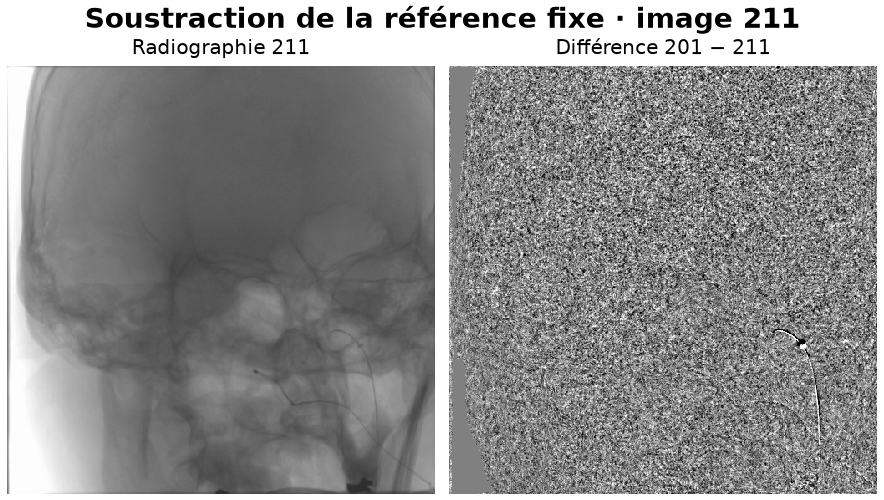

In [ ]:
afficher('intermediaires/comparaisons_filtres/difference.png', largeur=900)

La soustraction atténue les structures visibles dans les deux radiographies. Sur 211, elle fait apparaître une réponse claire et sombre autour du tracé à droite, avec du grain dans le fond. Ce grain motive le filtrage spatial suivant.

#### 1.2.2 Filtrage spatial : gaussien, médian et bilatéral

**Entrée.** Nous partons de la même différence signée dans les quatre essais. Le filtre gaussien calcule une moyenne pondérée des pixels voisins. Le filtre médian prend leur médiane. Le filtre bilatéral tient aussi compte des écarts d’intensité pour limiter le lissage à travers les contours.

```python
gaussien = cv2.GaussianBlur(difference, (5, 5), 1)
median = cv2.medianBlur(difference, 5)
sigma_couleur = 50 * float(np.ptp(difference)) / 255
bilateral = cv2.bilateralFilter(difference, 5, sigma_couleur, 50)
```

Le paramètre d’intensité 50 du premier essai sur une échelle 0–255 est converti dans l’échelle de la différence signée. La figure reprend la différence $I_{201}-I_{291}$. Les quatre vues utilisent la même échelle de gris pour comparer le grain et le contraste immédiatement après le filtrage.

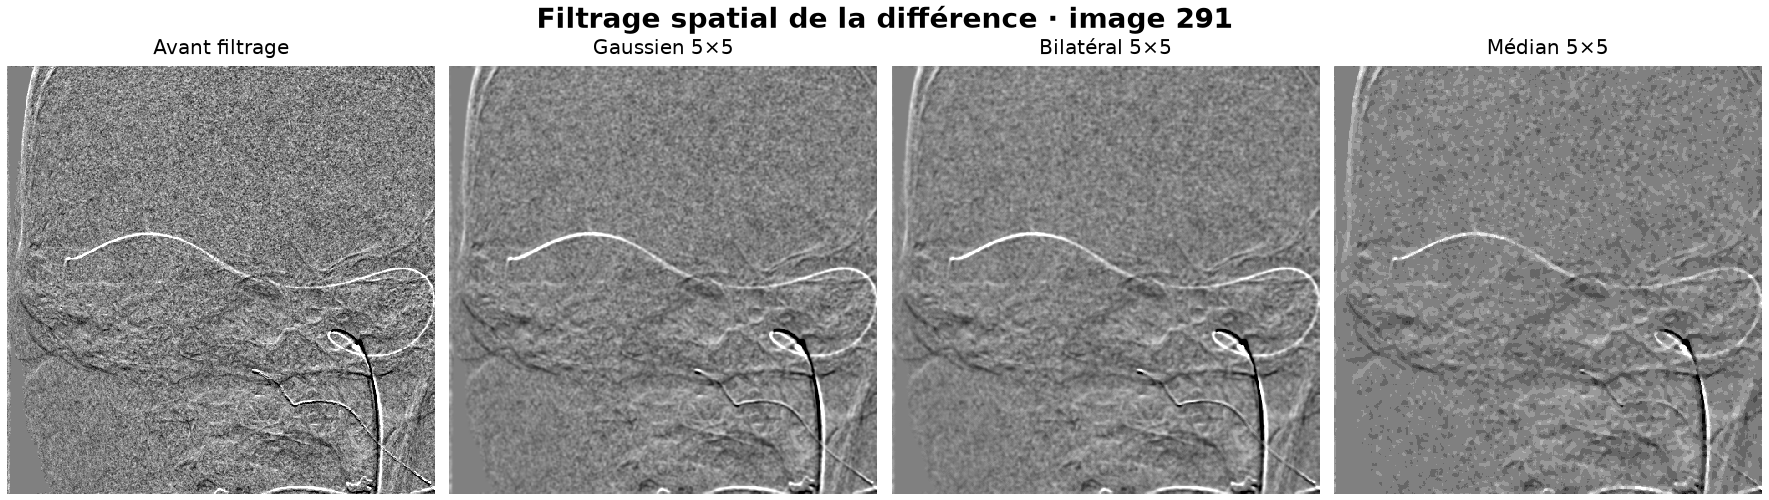

In [ ]:
afficher('intermediaires/comparaisons_filtres/spatial.png', largeur=900)

Le gaussien et le bilatéral atténuent le grain tout en laissant visible le tracé fin sur 291. Le médian laisse des aplats irréguliers et estompe certaines portions du tracé. Les sorties du gaussien et du bilatéral sont visuellement proches. Nous gardons le gaussien pour son lissage régulier.

#### 1.2.3 Filtrage spectral : passe-haut ou passe-bande

**Entrée.** Nous conservons le gaussien spatial, puis comparons l’image sans filtrage de Fourier, un passe-haut gaussien, un passe-haut de Butterworth ($D_0=12$, ordre 2) et le passe-bande gaussien. Le passe-haut atténue les variations lentes. Le passe-bande combine cette atténuation avec un passe-bas pour limiter les hautes fréquences résiduelles.

```python
passe_haut = 1 - np.exp(-distance2 / (2 * 10**2))
passe_bas = np.exp(-distance2 / (2 * 60**2))
passe_bande = passe_haut * passe_bas
```

Le masque fréquentiel multiplie la transformée centrée. La transformée inverse ramène la réponse dans le domaine spatial.

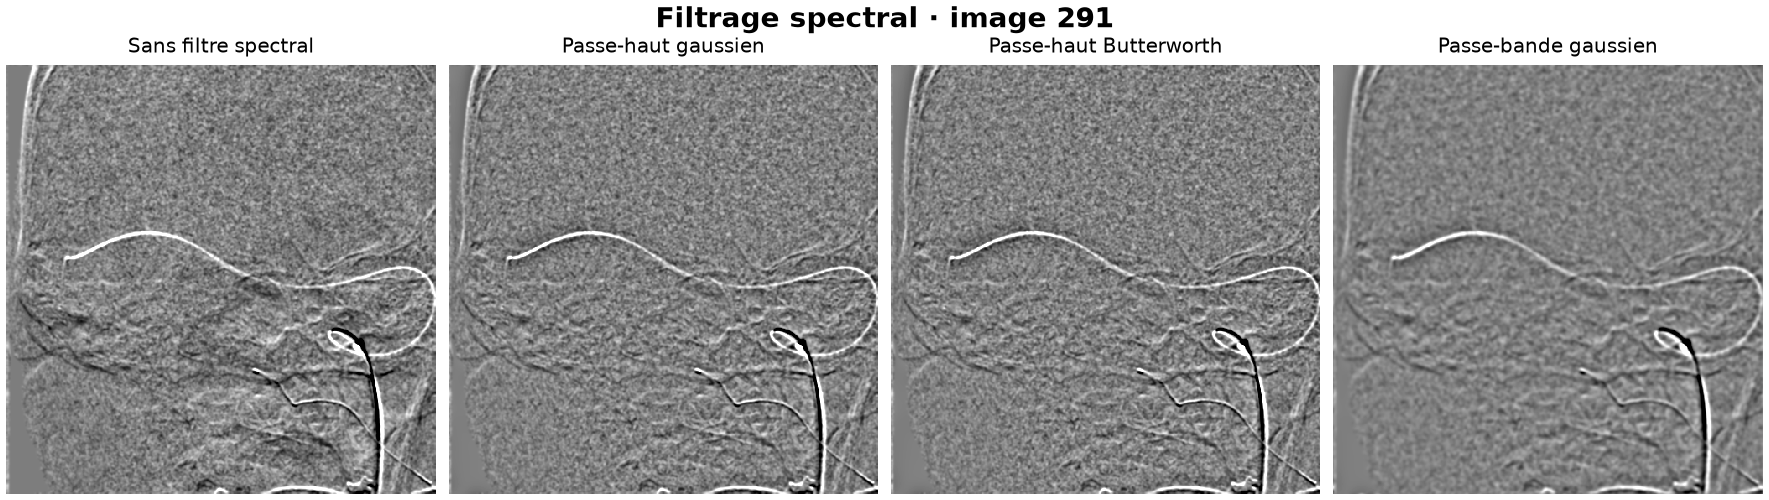

In [ ]:
afficher('intermediaires/comparaisons_filtres/spectral.png', largeur=900)

Les deux passe-haut laissent du grain autour du tracé. Le passe-bande l’atténue davantage, et la courbe reste visible sur une grande partie de l’image. Nous gardons cette réponse pour la transformation d’histogramme.

#### 1.2.4 Transformation d’histogramme : maximum ou percentile

**Entrée.** À la sortie du passe-bande, nous gardons les valeurs positives. Nous comparons un étirement jusqu’au maximum avec un étirement jusqu’au **99ᵉ percentile**. Les deux donnent une image 8 bits, mais avec le percentile, les valeurs au-dessus de cette borne saturent. Le reste de l’image exploite alors davantage la plage 0–255.

```python
positive = np.maximum(filtree, 0)
limite = np.percentile(positive, 99)
contraste = np.rint(255 * np.clip(positive / limite, 0, 1))
```

Le code complet protège le cas où la limite vaut zéro. Les deux cartes de contraste sont affichées sur la même échelle 0–255, directement après l’étirement.

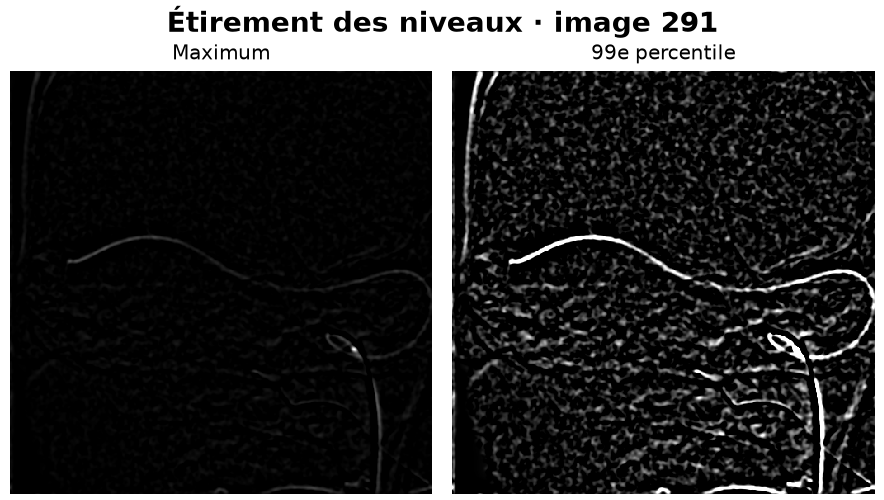

In [ ]:
afficher('intermediaires/comparaisons_filtres/histogramme.png', largeur=900)

L’étirement jusqu’au maximum donne une image sombre où une partie du tracé se distingue difficilement. Avec le 99ᵉ percentile, le tracé devient plus lumineux et plus facile à suivre. Des détails du fond ressortent aussi. Nous gardons le percentile pour rendre visibles les portions faibles avant le seuillage.

#### 1.2.5 Segmentation : choix du seuil

**Entrée.** Nous partons de la même carte de contraste. Otsu propose une coupure automatique. Nous testons plusieurs décalages positifs en unités de gris, ce qui demande une réponse plus forte avant de classer le pixel comme outil.

```python
otsu, _ = cv2.threshold(contraste, 0, 1, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
outil = contraste > min(otsu + 30, 255)
```

Les quatre masques montrent le résultat immédiat du seuillage, avant la morphologie.

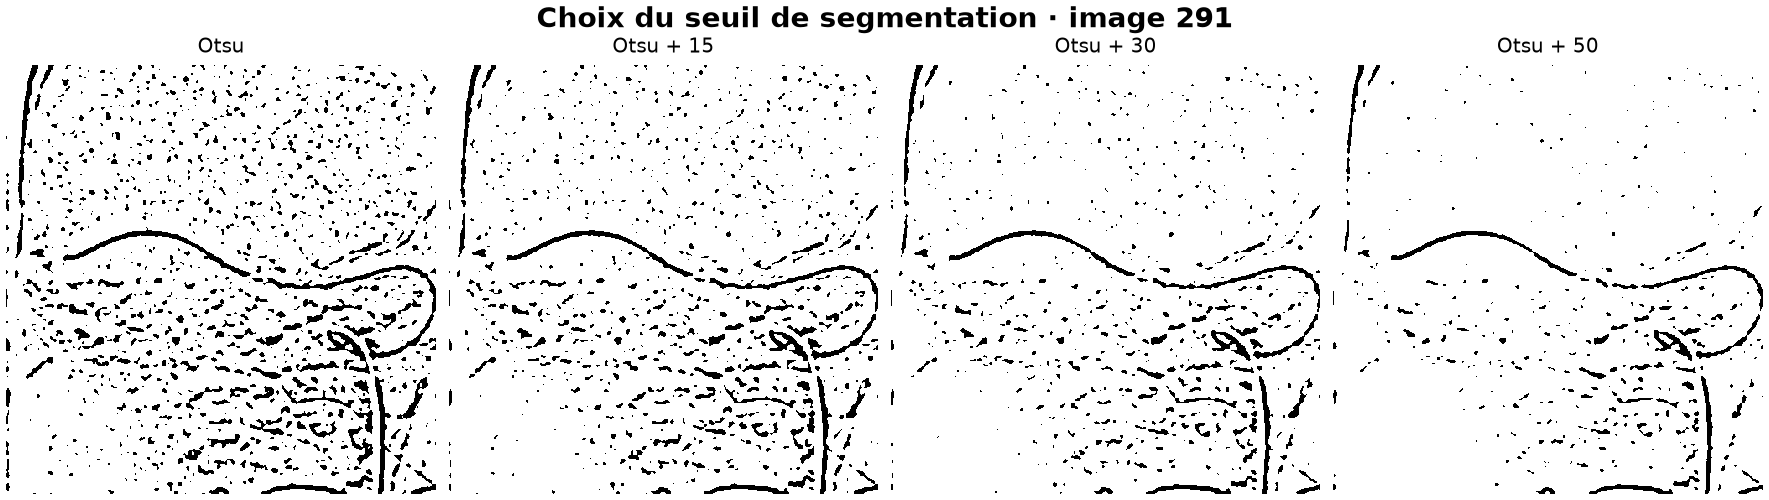

In [ ]:
afficher('intermediaires/comparaisons_filtres/segmentation.png', largeur=900)

Avec Otsu seul, beaucoup de points noirs se répartissent dans le fond. Quand le seuil augmente, ces points diminuent et certaines portions fines du tracé s’interrompent. Nous gardons Otsu + 30 pour préserver la continuité du tracé tout en retirant une partie des points isolés.

#### 1.2.6 Morphologie : composantes connexes et fermeture

Nous partons du masque d’Otsu + 30. Chaque composante connexe (8-connexité) est un groupe de pixels noirs reliés entre eux. Nous comparons six aires minimales, de 20 à 500 pixels, pour voir quelles parties du tracé subsistent quand on écarte les petites composantes.

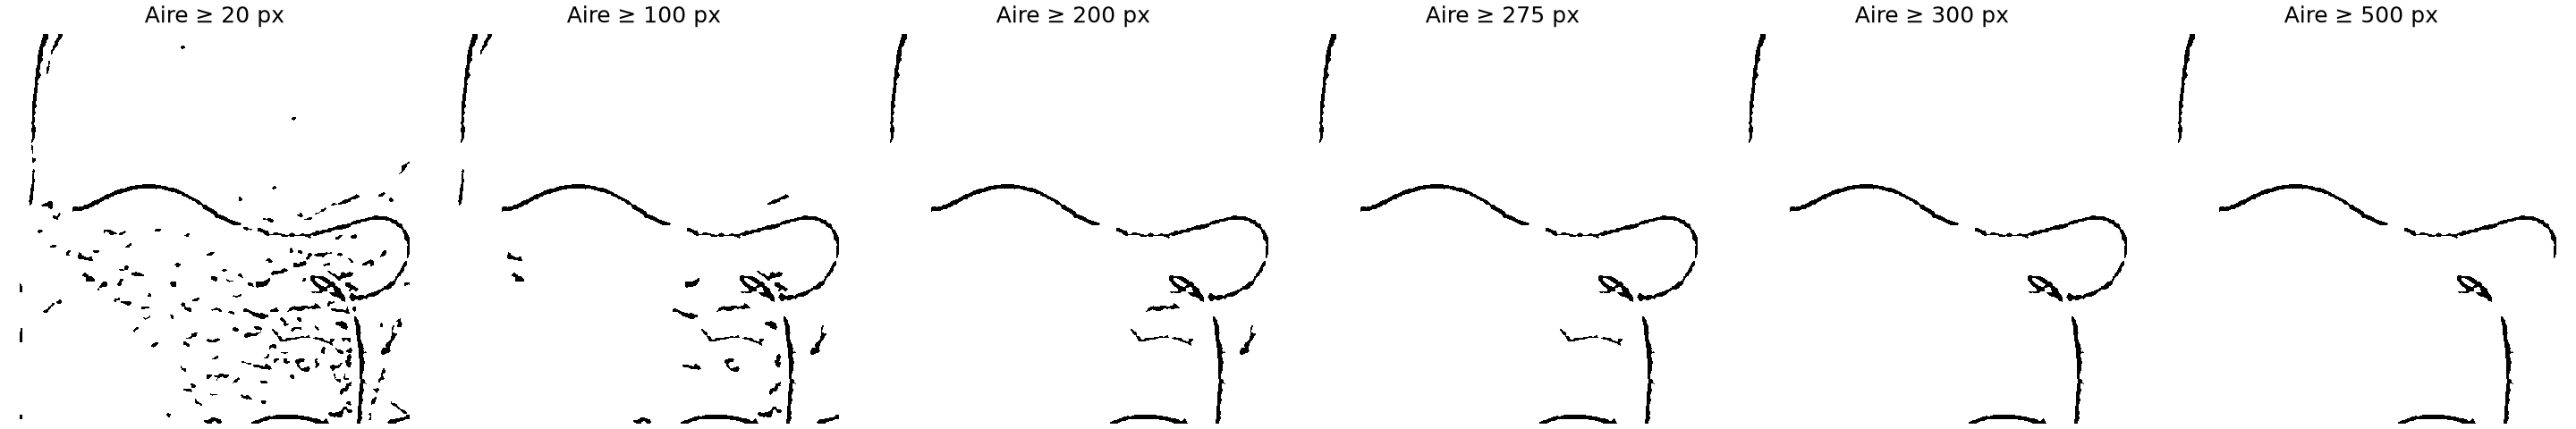

In [ ]:
afficher('intermediaires/aires_composantes/aires_291.png', largeur=1100)

Sur 291, passer de 20 à **300 pixels** retire de nombreuses taches et quelques fragments autour du fil. La boucle de droite est encore visible à 300 pixels. À 500 pixels, une partie de son retour disparaît. Nous retenons donc **300 pixels d’aire minimale** avant la fermeture.

La planche suivante compare la sélection par aire et les fermetures 3×3 et 5×5.

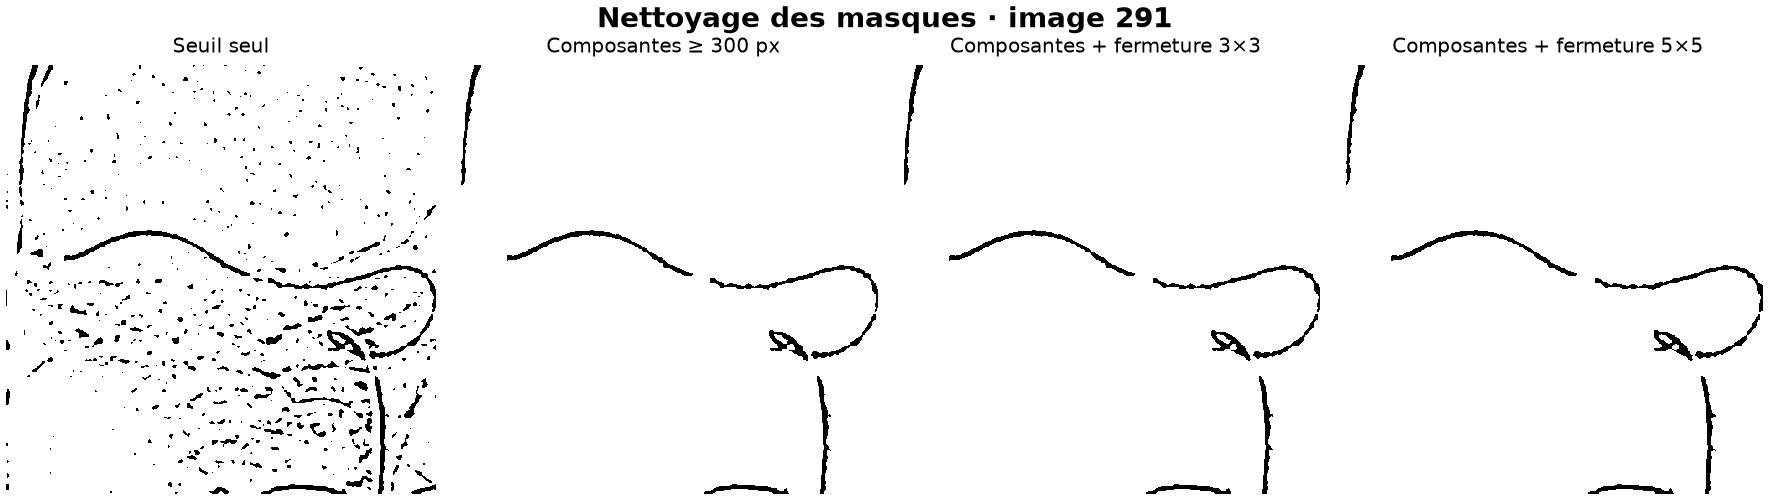

In [ ]:
afficher('intermediaires/comparaisons_filtres/morphologie.png', largeur=900)

Après la sélection des composantes de 300 pixels ou plus, la fermeture comble de petites coupures. Nous gardons le noyau elliptique **3×3** pour limiter l’élargissement des fragments par rapport au 5×5.

**Code de la segmentation commune, jusqu’à la fermeture**

Le code ci-dessous est extrait de [`segmentation.py`](segmentation.py). La même chaîne et les mêmes paramètres sont utilisés pour les neuf images. Le masque booléen interne marque l’outil avec `True`. À l’export, l’outil est noir (0) et le fond blanc (255 dans le PNG, soit 1 en binaire).

```python
AIRE_MINIMALE_COMPOSANTE = 300


def filtrer(reference, image):
    if reference.shape != image.shape:
        raise ValueError("Les deux images doivent avoir les mêmes dimensions.")

    # En flottants, la soustraction conserve les valeurs négatives.
    difference = reference.astype(np.float32) - image.astype(np.float32)
    gauss = cv2.GaussianBlur(difference, (5, 5), 1)

    hauteur, largeur = gauss.shape
    y, x = np.ogrid[:hauteur, :largeur]
    distance2 = (y - hauteur // 2)**2 + (x - largeur // 2)**2
    passe_haut = 1 - np.exp(-distance2 / (2 * 10**2))
    passe_bas = np.exp(-distance2 / (2 * 60**2))
    passe_bande = (passe_haut * passe_bas).astype(np.float32)

    # On centre les basses fréquences pour appliquer le passe-bande radial.
    spectre = np.fft.fftshift(cv2.dft(gauss, flags=cv2.DFT_COMPLEX_OUTPUT), axes=(0, 1))
    spectre_filtre = np.fft.ifftshift(spectre * passe_bande[:, :, None], axes=(0, 1))
    filtree = cv2.idft(spectre_filtre, flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT)

    return difference, gauss, filtree


def segmenter_outil(reference, image):
    """Renvoie la réponse de chaque filtre et les masques de la chaîne complète."""
    difference, gauss, filtree = filtrer(reference, image)
    # Un objet qui assombrit l’image donne une différence positive.
    positive = np.maximum(filtree, 0)
    limite = np.percentile(positive, 99)
    contraste = np.zeros_like(positive, dtype=np.uint8)
    if limite > 0:
        contraste = np.rint(255 * np.clip(positive / limite, 0, 1)).astype(np.uint8)

    otsu, _ = cv2.threshold(contraste, 0, 1, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
    outil = (contraste > min(otsu + 30, 255)).astype(np.uint8)
    _, etiquettes, stats, _ = cv2.connectedComponentsWithStats(outil, connectivity=8)
    garder = stats[:, cv2.CC_STAT_AREA] >= AIRE_MINIMALE_COMPOSANTE
    garder[0] = False  # L’étiquette 0 correspond au fond.
    composantes = garder[etiquettes].astype(np.uint8)
    noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    masque = cv2.morphologyEx(composantes, cv2.MORPH_CLOSE, noyau).astype(bool)
    # Les vues binaires affichent les détections en noir.
    return {
        "Soustraction": difference,
        "Filtrage spatial": gauss,
        "Filtrage spectral": filtree,
        "Contraste au percentile 99": contraste,
        "Otsu + 30": 1 - outil,
        f"Composantes ≥ {AIRE_MINIMALE_COMPOSANTE} px": 1 - composantes,
        "Fermeture 3×3": ~masque,
    }, masque
```

#### 1.2.7 Exclusion de trois zones de bord

Après la fermeture, nous supprimons les détections dans trois rectangles fixes, repérés sur les superpositions de la séquence :

- **En haut à gauche** : $x < 45$ et $y < 240$, où le bord du crâne apparaît en rouge.
- **En bas** : $290 \leq x < 438$ et $y \geq 485$, où une bande horizontale apparaît en vert.
- **En bas à droite** : $x \geq 456$ et $y \geq 348$, où le masque vert suit par endroits le bord de l’image.

Ces coordonnées s’appliquent aux images de 512 × 512 pixels et sont redimensionnées pour les autres dimensions. La bande inférieure s’arrête à gauche du tracé descendant du microcathéter. Le rectangle inférieur droit commence à droite de ce tracé. Sur les images 201 à 291, les trois rectangles ne recouvrent aucun pixel des annotations TIFF dilatées. [Code du masque spatial](separation_outils.py)

La rangée du haut montre les détections avant nettoyage, avec les trois rectangles à exclure en **bleu**. La rangée du bas montre les mêmes radiographies après suppression des pixels dans ces zones. C’est la dernière étape de nettoyage du masque, juste avant la séparation des outils.

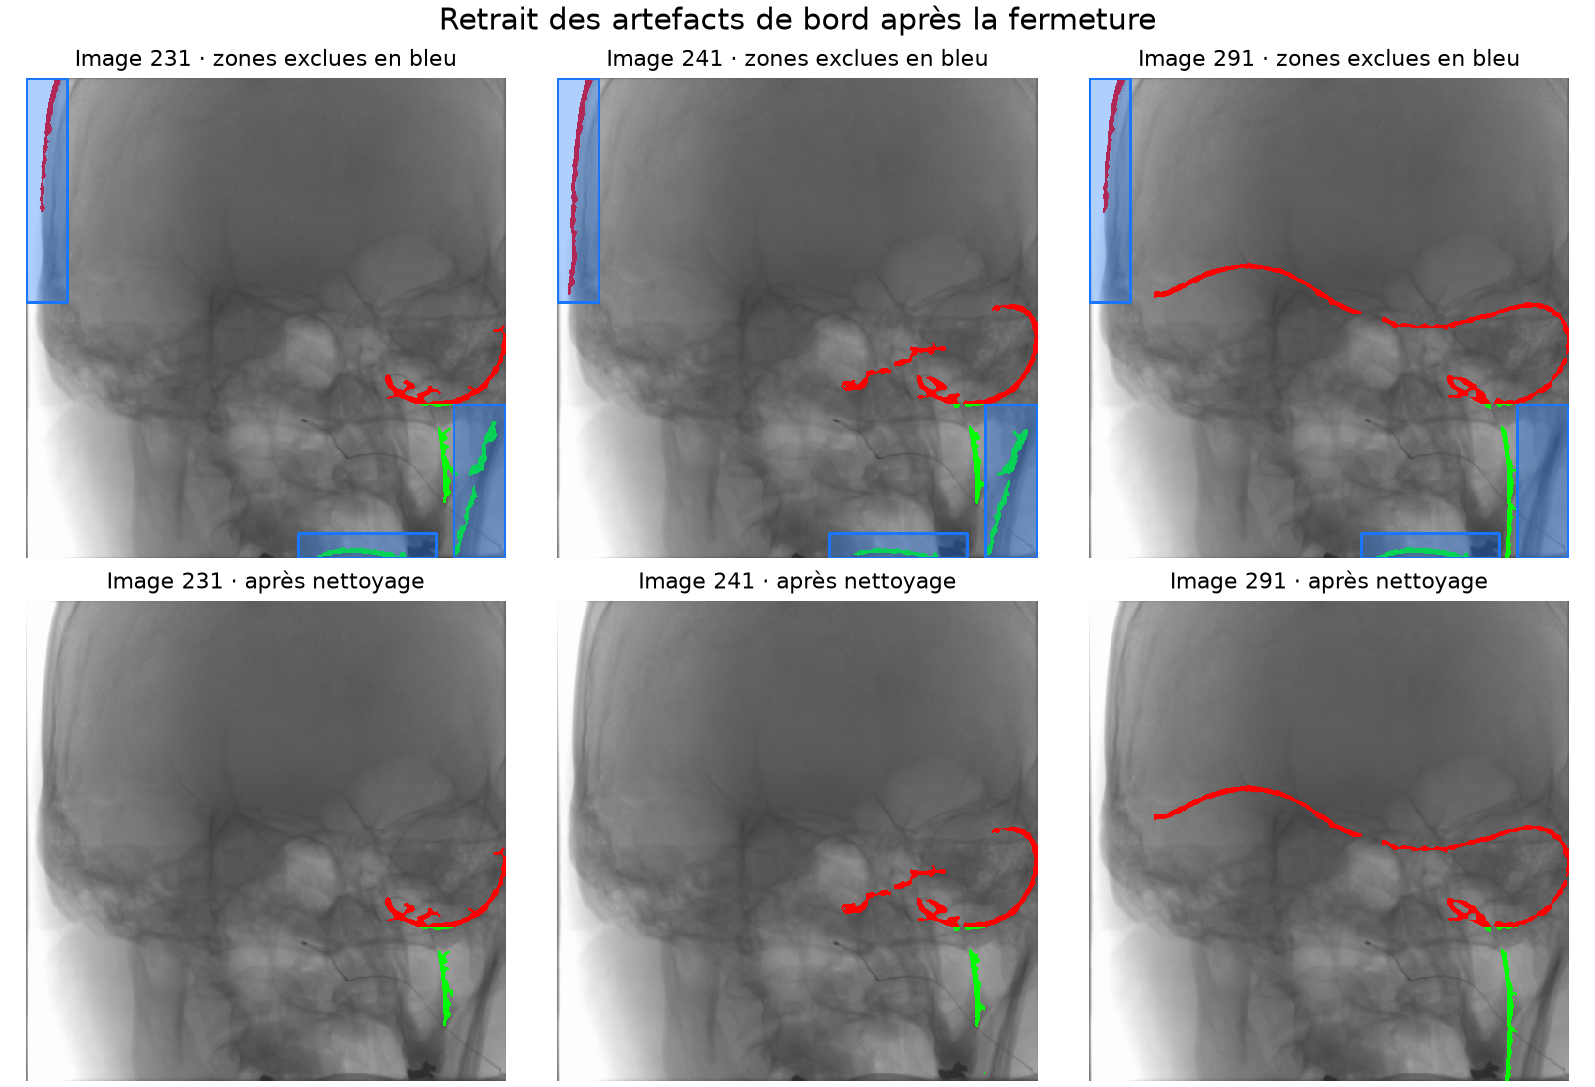

In [ ]:
from io import BytesIO

import cv2
import matplotlib.pyplot as plt
import numpy as np

from segmentation import lire_image, segmenter_outil
from separation_outils import separer_outils, zone_sans_artefacts
from visualisation import superposer

donnees = Path("catheter")
reference = lire_image(donnees / "frame_201.png")
numeros = (231, 241, 291)
fig, axes = plt.subplots(2, 3, figsize=(11, 7.5), layout="constrained")
fig.suptitle("Retrait des artefacts de bord après la fermeture", fontsize=15)

for colonne, numero in enumerate(numeros):
    image = lire_image(donnees / f"frame_{numero}.png")
    _, masque_ferme = segmenter_outil(reference, image)
    zone = zone_sans_artefacts(image.shape)

    # Couleurs provisoires pour voir les détections à enlever sous le bleu.
    avant = cv2.cvtColor(superposer(image, *separer_outils(masque_ferme)), cv2.COLOR_BGR2RGB)
    bleu = np.array([25, 119, 255], dtype=np.float32)
    avant[~zone] = np.rint(0.66 * avant[~zone] + 0.34 * bleu).astype(np.uint8)
    contours, _ = cv2.findContours((~zone).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(avant, contours, -1, (25, 119, 255), 2)

    apres = cv2.cvtColor(superposer(image, *separer_outils(masque_ferme & zone)), cv2.COLOR_BGR2RGB)
    for rang, (vue, titre) in enumerate((
        (avant, f"Image {numero} · zones exclues en bleu"),
        (apres, f"Image {numero} · après nettoyage"),
    )):
        axe = axes[rang, colonne]
        axe.imshow(vue, interpolation="nearest")
        axe.set_title(titre, fontsize=11)
        axe.axis("off")

tampon = BytesIO()
fig.savefig(tampon, format="png", dpi=145)
plt.close(fig)
display(Image(data=tampon.getvalue(), format="png", width=900))

#### 1.2.8 Délimitation entre le guidewire et le microcathéter

Les deux annotations TIFF montrent la position relative des instruments. Sur l’image 291, `291_GuideWire.tiff` suit la longue courbe supérieure et sa boucle. `291_MicroCath.tiff` suit le segment qui descend à droite. La planche superpose ces tracés à la radiographie.

Sur les TIFF bruts de 211 à 291, la ligne 348 place les 3 340 pixels GuideWire au-dessus et 1 463 des 1 577 pixels MicroCath au-dessous ou sur la ligne (92,8 %). La coupure a été choisie sur la même séquence que celle évaluée.

Nous appliquons la coupe **après la fermeture et l’exclusion des zones de bord**, avec les lignes $y < 348$ attribuées au guidewire et les lignes $y \geq 348$ au microcathéter. La coordonnée $y$ croît du haut vers le bas et commence à zéro. La ligne est redimensionnée en proportion de la hauteur de l’image. La même coupure est appliquée aux neuf images.

[Code de la séparation géométrique](separation_outils.py)

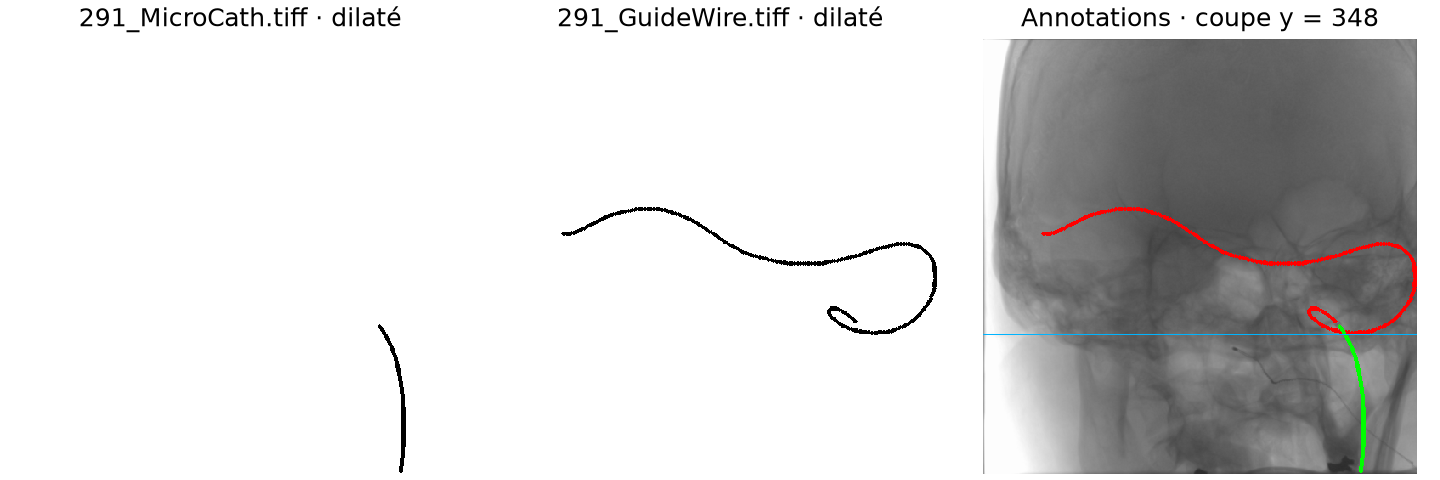

In [ ]:
afficher('validation_par_outil/annotations_291.png', largeur=900)

[Annotations de l’image 291](results/validation_par_outil/annotations_291.png)

## 2. Validation et évaluation

Nous comparons les masques des neuf images **211 à 291** aux annotations TIFF de la même image. Sur les images 201 à 291, les trois zones exclues sont en dehors des annotations dilatées des instruments. Pour chaque outil, nous dilatons les pixels annotés avec un disque de rayon 2 pixels. Sur les masques binaires, le **SAD** compte les pixels différents et la **MSE** donne leur proportion. Pour le **PSNR**, la valeur maximale du masque vaut 1. Les vues permettent de localiser les erreurs que ces scores résument.

[Code de l’évaluation par outil](validation_par_outil.py) · [Mesures et tracés exportés](results/validation_par_outil/)

### 2.1 Microcathéter

**Validation visuelle.** Après le nettoyage des bords, nous prenons les détections des lignes $y \geq 348$ et les affichons en vert. Le TIFF `MicroCath` dilaté sert de référence. Comme le microcathéter se déplace peu, la soustraction peut faire disparaître les parties déjà présentes dans la référence 201.

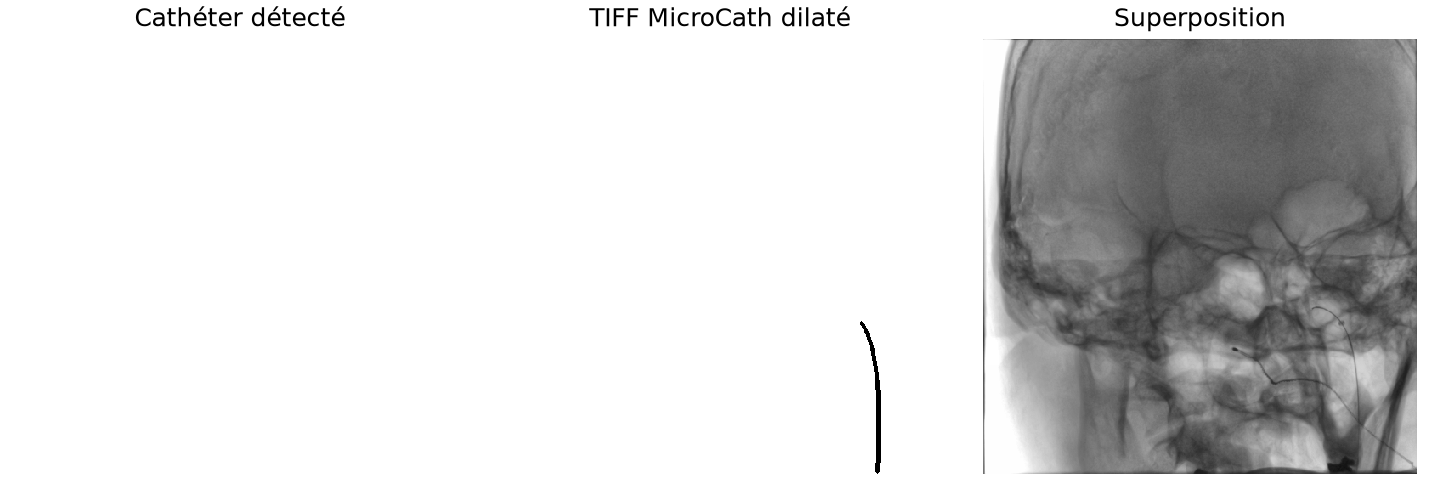

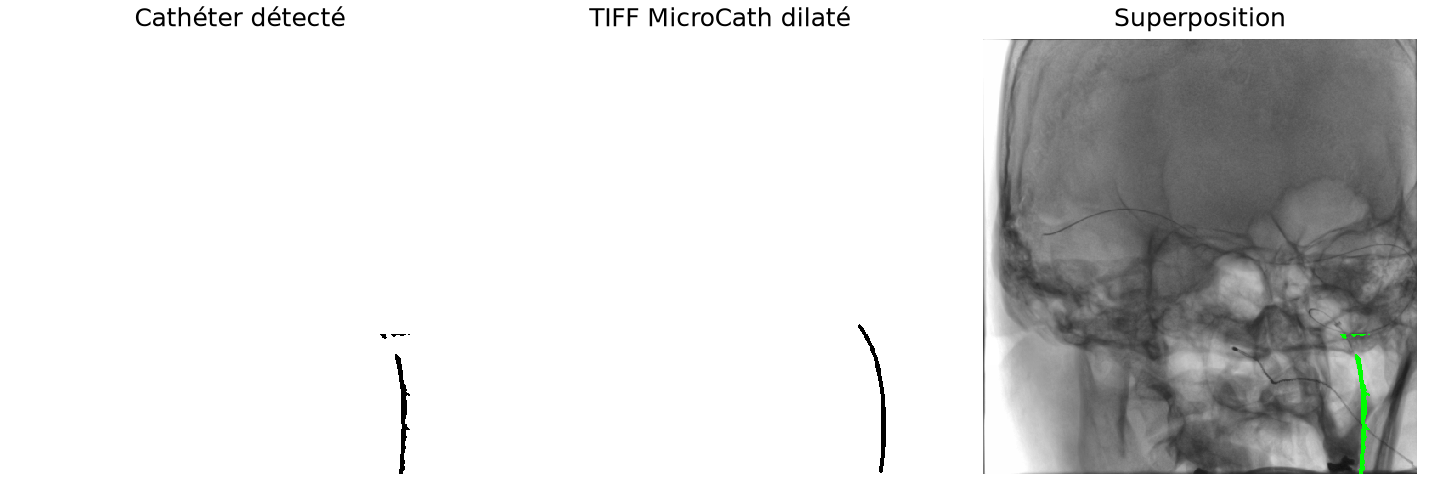

In [ ]:
afficher('validation_par_outil/catheter/comparaison_211.png', largeur=900)
afficher('validation_par_outil/catheter/comparaison_291.png', largeur=900)


#### Évaluation quantitative

| Image | SAD (pixels) | MSE | PSNR (dB) |
|---:|---:|---:|---:|
| 211 | 889 | 0,003391 | 24,70 |
| 221 | 903 | 0,003445 | 24,63 |
| 231 | 1 166 | 0,004448 | 23,52 |
| 241 | 1 052 | 0,004013 | 23,97 |
| 251 | 966 | 0,003685 | 24,34 |
| 261 | 546 | 0,002083 | 26,81 |
| 271 | 547 | 0,002087 | 26,81 |
| 281 | 550 | 0,002098 | 26,78 |
| 291 | 516 | 0,001968 | 27,06 |

| Mesure | Moyenne | Écart-type |
|---|---:|---:|
| SAD | 792,8 | 239,2 |
| MSE | 0,003024 | 0,000912 |
| PSNR (dB) | 25,40 | 1,35 |

En moyenne, le masque contient **261 pixels détectés hors de l’annotation** par image et retrouve **39,2 %** des pixels annotés. Sur 211, le masque est vide. Sur 291, il retrouve une partie du segment descendant.

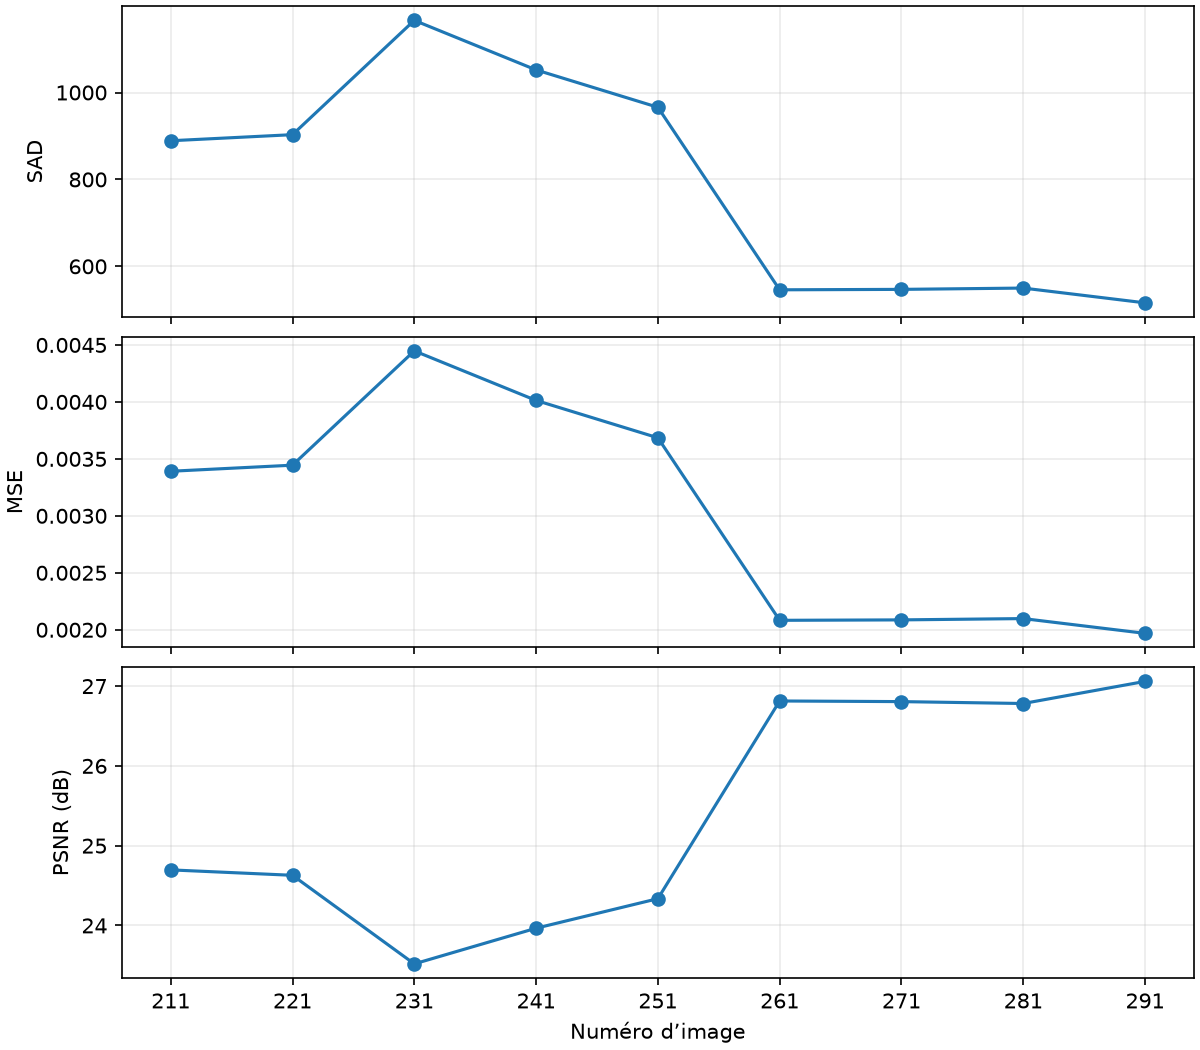

In [ ]:
afficher('validation_par_outil/catheter/scores.png', largeur=690)


### 2.2 Guidewire

**Validation visuelle.** Après le nettoyage des bords, le masque du guidewire prend les détections des lignes $y < 348$ et les affiche en rouge. Nous comparons ce masque au tracé complet du TIFF `GuideWire` dilaté. Les contours du fond qui subsistent hors de la zone exclue apparaissent également dans le masque rouge.

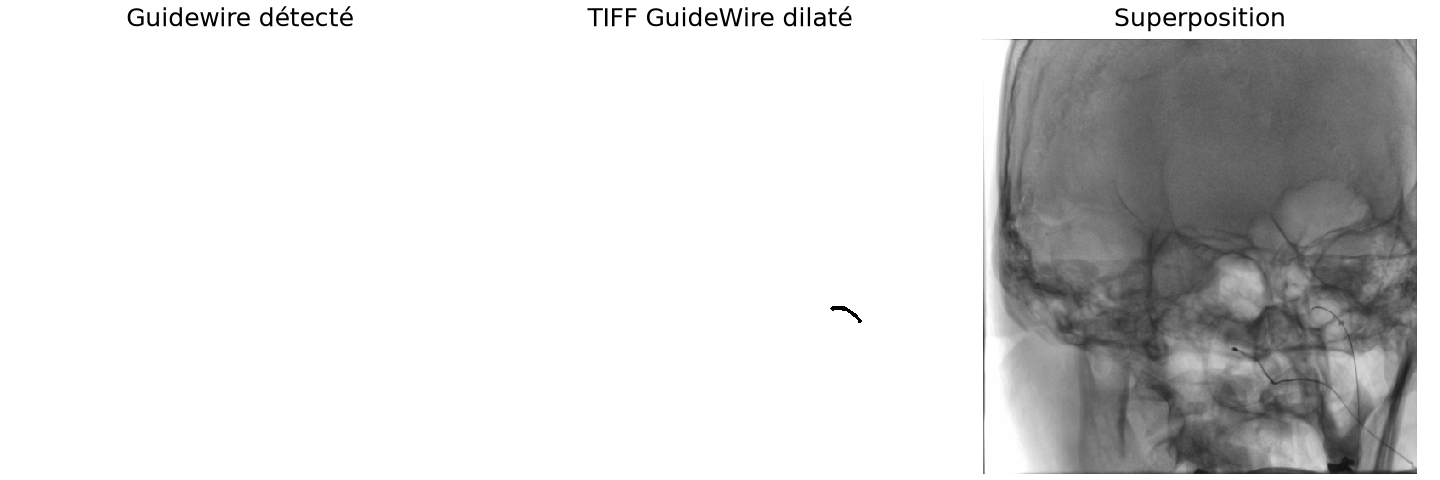

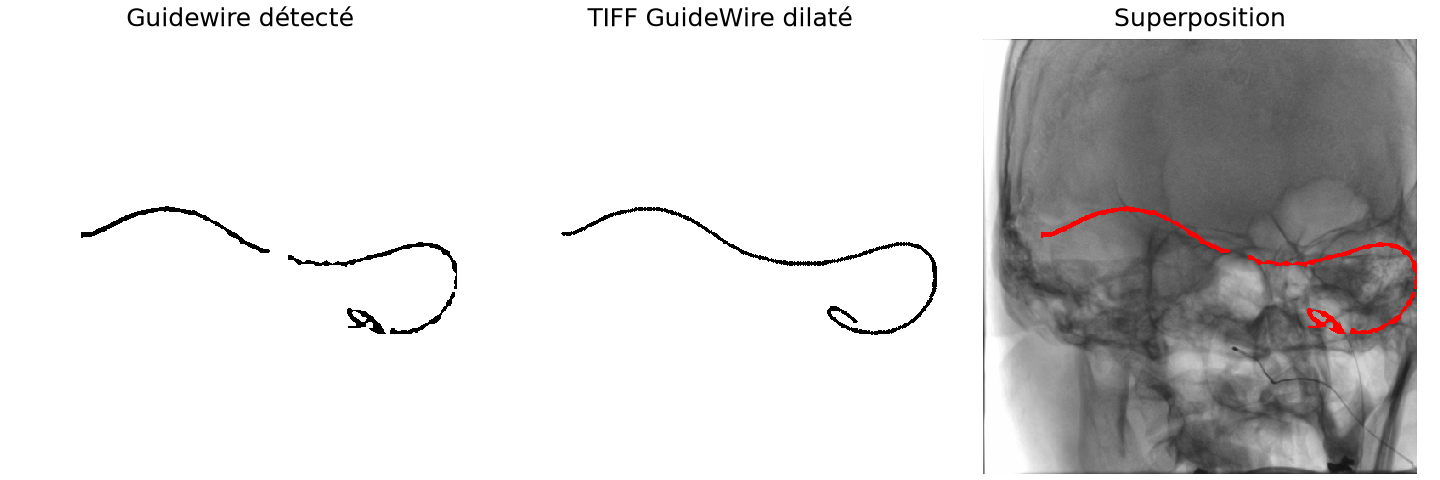

In [ ]:
afficher('validation_par_outil/guidewire/comparaison_211.png', largeur=900)
afficher('validation_par_outil/guidewire/comparaison_291.png', largeur=900)


#### Évaluation quantitative

| Image | SAD (pixels) | MSE | PSNR (dB) |
|---:|---:|---:|---:|
| 211 | 185 | 0,000706 | 31,51 |
| 221 | 425 | 0,001621 | 27,90 |
| 231 | 792 | 0,003021 | 25,20 |
| 241 | 1 393 | 0,005314 | 22,75 |
| 251 | 807 | 0,003078 | 25,12 |
| 261 | 1 292 | 0,004929 | 23,07 |
| 271 | 944 | 0,003601 | 24,44 |
| 281 | 923 | 0,003521 | 24,53 |
| 291 | 1 397 | 0,005329 | 22,73 |

| Mesure | Moyenne | Écart-type |
|---|---:|---:|
| SAD | 906,4 | 394,8 |
| MSE | 0,003458 | 0,001506 |
| PSNR (dB) | 25,25 | 2,68 |

En moyenne, le masque contient **526 pixels détectés hors de l’annotation** par image et retrouve **68,4 %** des pixels annotés. Sur 291, les deux grandes portions de la courbe sont visibles, avec une coupure au milieu.

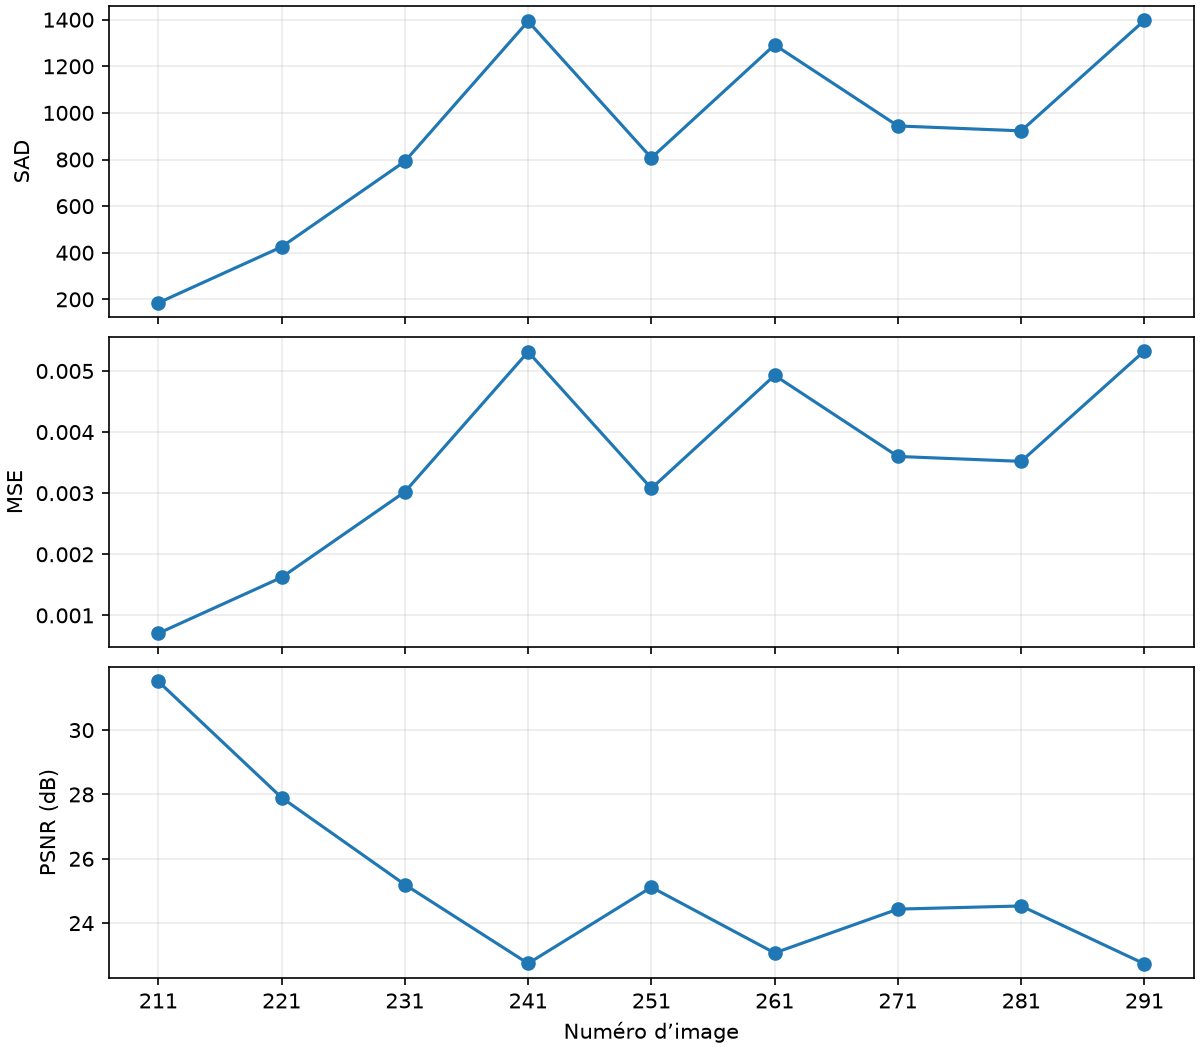

In [ ]:
afficher('validation_par_outil/guidewire/scores.png', largeur=690)


### 2.3 Réunion des deux masques

Les zones haute et basse sont disjointes. Leur union reconstitue exactement le masque commun obtenu après la fermeture et l’exclusion des trois zones. La superposition montre le **microcathéter en vert** et le **guidewire en rouge**. La référence globale est l’union des deux annotations dilatées.

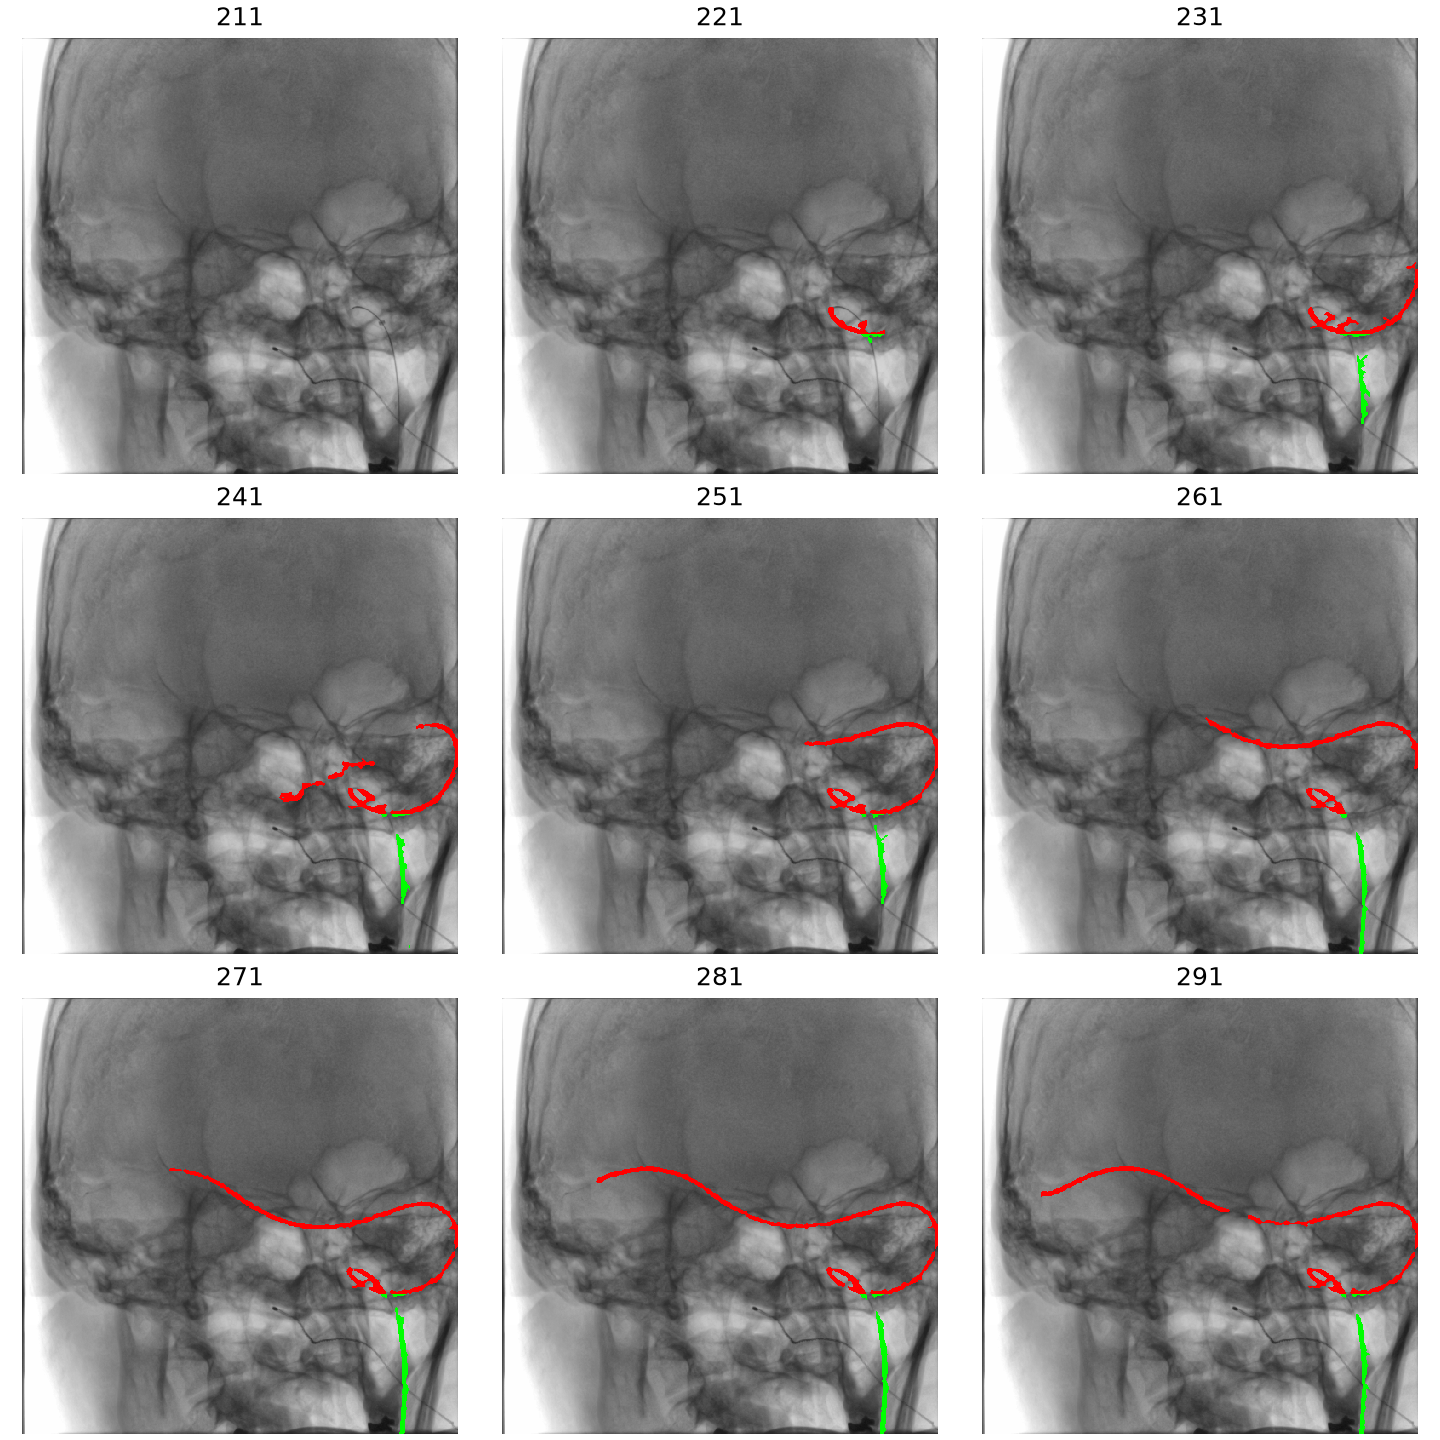

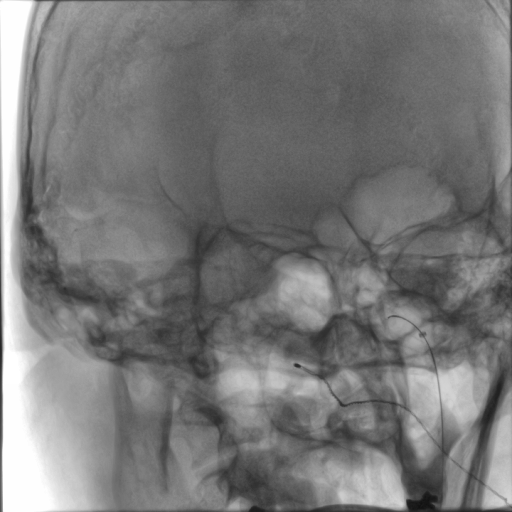

In [ ]:
afficher('validation_par_outil/union/detections_completes.png', largeur=900)
afficher('validation_par_outil/union/animation.gif', largeur=512)


| Mesure | Moyenne | Écart-type |
|---|---:|---:|
| SAD | 1 598,7 | 374,9 |
| MSE | 0,006098 | 0,001430 |
| PSNR (dB) | 22,27 | 1,02 |

Le masque complet contient en moyenne **750 pixels détectés hors de l’annotation** par image.

## Conclusion

La soustraction avec la référence 201 fait ressortir les structures qui changent au cours de la séquence. Les filtres spatial et spectral rendent le tracé plus lisible. Le filtrage par aire et l’exclusion des trois zones de bord éliminent des détections parasites. La fermeture raccorde certains fragments. La coupure à la ligne 348 permet de superposer le guidewire en rouge et le microcathéter en vert.

Sur les neuf images, le masque réuni donne un SAD moyen de 1 599 pixels et un PSNR moyen de 22,27 dB. L’évaluation contre les TIFF montre les limites de cette méthode. Le rappel moyen par image est de 39,2 % pour le microcathéter et de 68,4 % pour le guidewire. Le microcathéter bouge peu, ce qui atténue son tracé lors de la soustraction. Sur 211, les deux masques sont vides malgré un PSNR relativement élevé, car le fond occupe la majorité de l’image. Les zones exclues et la ligne de séparation ont été choisies sur cette séquence. Leur validité sur un autre cadrage reste à vérifier.